# Parameter-level hybridization: a hypernetwork for temperature-dependent viscoelasticity

This notebook illustrates hybridization at the level of the material parameters. Each
coefficient of a constitutive model becomes a module of an external variable, here the
temperature $T$, and a wrapper extends the signature of the model from $\boldsymbol\varepsilon$ to
$(\boldsymbol\varepsilon, T)$. At each step, the wrapper evaluates the parameter modules at the
current temperature and passes the resulting parameters to the unchanged model. When the
parameter modules are networks, they form a **hypernetwork**, that is a network that generates
the parameters of another model (Ha, Dai and Le, 2017), here a physics-based constitutive model.

The model is a generalized Maxwell model, whose parameters are the Prony series
$(E_\infty, E_i, \tau_i)_{i=1..N}$. Four models of its temperature dependence are compared:

- **Arrhenius** and **WLF**: time-temperature superposition, in which all relaxation times are
  multiplied by a single shift factor, $\tau_i(T) = \tau_i^\text{ref}\,a_T(T)$, given by a
  classical law, the moduli being constant;
- **hypernetwork**: the Prony series is generated by networks of the temperature, with one shift
  factor per branch and a structure that keeps the generated relaxation times physically
  admissible;
- **free hypernetwork**: the Prony series is generated by networks of the temperature, with
  positivity as the only constraint.

The data is generated by a thermorheologically complex material, for which no single shift
factor exists, and whose moduli also depend on the temperature. The setting is small strain, and
thermal strains are not considered.

In [2]:
import time

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optimistix as optx
import pandas as pd
import paramax

import jaxmat
import jaxmat.materials as jm
from jaxmat.nn.icnn import ICNN
from jaxmat.parameters import (
    AbstractParameter,
    Expression,
    Positive,
    evaluate_parameters,
)
from jaxmat.tensors import SymmetricTensor2
from jaxmat.utils import partition_by_node_names

jax.config.update("jax_platform_name", "cpu")
print(
    f"jaxmat {jaxmat.__version__}, jax {jax.__version__}, float64: {jax.config.jax_enable_x64}"
)

# Colours and line styles of the models
STYLE = {
    "Arrhenius": dict(color="darkorange", ls="--"),
    "WLF": dict(color="forestgreen", ls="-."),
    "Hypernetwork, free": dict(color="darkmagenta", ls=":"),
    "Hypernetwork": dict(color="royalblue", ls="-"),
}
modelS = ["Arrhenius", "WLF", "Hypernetwork, free", "Hypernetwork"]

T_REF, R_GAS, NU, EPS0, N = 300.0, 8.314462618, 0.3, 1e-3, 4

jaxmat 0.1, jax 0.10.2, float64: True


## Parameters as modules and the temperature wrapper

In `jaxmat`, every material coefficient of a behavior is declared as a `parameter()` field, which
accepts either a constant or an `AbstractParameter`, a module evaluated at the external
variables. The wrapper `TemperatureDependent(behavior)` takes inputs $(\boldsymbol\varepsilon, T)$,
replaces each `AbstractParameter` of the behavior by its value at $T$, and calls the
`constitutive_update` of the resolved behavior. The generalized Maxwell behavior
(`GeneralizedMaxwell`) is used unchanged; its update over a step uses the relaxation times at the
current temperature, so that a varying temperature is integrated along the history.

The model is driven by an isochoric uniaxial strain $\boldsymbol\varepsilon(t) =
\varepsilon(t)\,\operatorname{diag}(1, -\tfrac12, -\tfrac12)$ and a temperature history $T(t)$.
In a relaxation test, $\varepsilon = \varepsilon_0$ is applied at $t = 0$ and held, which gives the
relaxation modulus $E(t; T) = (1 + \nu)\,\sigma_{11}(t)/\varepsilon_0$ (same Poisson ratio
$\nu = 0.3$ in all branches).

In [3]:
def generalized_maxwell(E_inf, E_branches, relaxation_times):
    """Temperature-dependent generalized Maxwell model; any coefficient may be a parameter module."""
    return jm.TemperatureDependent(
        jm.GeneralizedMaxwell(
            elasticity=jm.LinearElasticIsotropic(E=E_inf, nu=NU),
            Nbranch=N,
            viscous_branches=jm.LinearElasticIsotropic(
                E=E_branches, nu=jnp.full(N, NU)
            ),
            relaxation_times=relaxation_times,
        )
    )


DIRECTION = jnp.array([1.0, -0.5, -0.5, 0.0, 0.0, 0.0])  # isochoric uniaxial strain


def axial_stress(model, eps_history, T_history, t):
    """Axial stress along a time grid t, for strain and temperature histories, from rest."""
    model = paramax.unwrap(model)

    def step(state, args):
        eps, T, dt = args
        strain = SymmetricTensor2(array=eps * DIRECTION)
        sig, state = model.constitutive_update((strain, T), state, dt)
        return state, sig[0, 0]

    dt = jnp.diff(jnp.concatenate([jnp.zeros(1), t]))
    _, sig11 = jax.lax.scan(step, model.init_state(), (eps_history, T_history, dt))
    return sig11


def relaxation_modulus(model, T_history, t):
    """Relaxation modulus for a strain EPS0 applied over the first step and held."""
    return (1 + NU) * axial_stress(model, jnp.full(t.shape, EPS0), T_history, t) / EPS0

## Reference material and data

The reference material has four branches: two fast branches whose relaxation times follow an
Arrhenius law, like a secondary relaxation, and two slow branches following a WLF law, like the
primary relaxation,

$$
\ln a^\text{Arr}(T) = \frac{Q}{R}\Bigl(\frac1T - \frac1{T_\text{ref}}\Bigr), \qquad
\log_{10} a^\text{WLF}(T) = -\frac{C_1 (T - T_\text{ref})}{C_2 + T - T_\text{ref}},
$$

with $Q = 80$ kJ/mol, $C_1 = 8.86$, $C_2 = 101.6$ K and $T_\text{ref} = 300$ K. The relaxation
times at $T_\text{ref}$ are $\tau_i = (0.03, 1, 30, 1000)$ s. Since the two groups of branches
shift differently, no single shift factor maps the relaxation curves onto each other.

The moduli also depend on the temperature: the equilibrium modulus is entropic,
$E_\infty(T) = E_\infty^\text{ref}\,T/T_\text{ref}$, and the branch moduli decrease linearly,
$E_i(T) = E_i^\text{ref}\,[1 - \beta (T - T_\text{ref})]$, with $E_\infty^\text{ref} = 50$ MPa,
$E_i^\text{ref} = (300, 200, 150, 100)$ MPa and $\beta = 4 \times 10^{-3}\,\text{K}^{-1}$.

Relaxation tests are simulated at six temperatures, from 280 to 330 K in steps of 10 K, with
41 log-spaced times from $10^{-3}$ to $10^{3}$ s (the strain is applied over the first step); the
34 times in $[10^{-2}, 10^{3}]$ s are used, with 2% Gaussian noise on the modulus. The models are
calibrated on the tests at 290, 300 and 320 K. The tests at 310 K (interpolation) and at 280 and
330 K (extrapolation) are held out.

An extrapolation test, not used for calibration, sweeps the temperature from 260 to 350 K, well
beyond the training range. At each temperature, the Prony series is evaluated and the relaxation
modulus is computed at fixed times $t^* \in \{0.1, 1, 10, 100\}$ s,

$$
E(t^*; T) = E_\infty(T) + \sum_{i=1}^{N} E_i(T)\,\exp\bigl(-t^*/\tau_i(T)\bigr),
$$

which is the isochronal modulus measured in a temperature sweep.

In [4]:
def log_shift_arrhenius(T, Q):
    return Q / R_GAS * (1.0 / T - 1.0 / T_REF)


def log_shift_wlf(T, C1, C2):
    return -jnp.log(10.0) * C1 * (T - T_REF) / (C2 + T - T_REF)


class ReferenceRelaxationTimes(AbstractParameter):
    tau_ref: jax.Array

    def evaluate(self, T):
        fast = log_shift_arrhenius(T, 80e3)
        slow = log_shift_wlf(T, 8.86, 101.6)
        return self.tau_ref * jnp.exp(jnp.stack([fast, fast, slow, slow]))


class ReferenceModulus(AbstractParameter):
    """E(T) = E_ref [1 + slope (T - T_ref)]"""

    E_ref: jax.Array
    slope: float = eqx.field(static=True)

    def evaluate(self, T):
        return self.E_ref * (1.0 + self.slope * (T - T_REF))


E_inf_ref, E_ref, tau_ref = (
    50.0,
    jnp.array([300.0, 200.0, 150.0, 100.0]),
    jnp.array([0.03, 1.0, 30.0, 1000.0]),
)
reference_moduli = {
    "E_inf": ReferenceModulus(
        E_inf_ref, slope=1.0 / T_REF
    ),  # entropic, E_inf proportional to T
    "E_branches": ReferenceModulus(E_ref, slope=-4e-3),  # softening branches
}
reference = generalized_maxwell(
    reference_moduli["E_inf"],
    reference_moduli["E_branches"],
    ReferenceRelaxationTimes(tau_ref),
)

t = jnp.logspace(-3, 3, 41)
window = t >= 1e-2 - 1e-12
temperatures = jnp.array([280.0, 290.0, 300.0, 310.0, 320.0, 330.0])
held_out = jnp.array([280.0, 310.0, 330.0])
train = jnp.logical_not(jnp.isin(temperatures, held_out))


@eqx.filter_jit
def isothermal_curves(model, temperatures):
    return jax.vmap(lambda T: relaxation_modulus(model, jnp.full(t.shape, T), t))(
        temperatures
    )


E_true = isothermal_curves(reference, temperatures)
noise_level = 0.02
E_data = E_true * (1 + noise_level * jax.random.normal(jax.random.key(0), E_true.shape))


def isochronal_modulus(model, T, t_star):
    """Relaxation modulus at time t_star from the Prony series resolved at temperature T."""
    resolved = evaluate_parameters(paramax.unwrap(model).behavior, T)
    E_inf, E_i = resolved.elasticity.E, resolved.viscous_branches.E
    return E_inf + jnp.sum(E_i * jnp.exp(-t_star / resolved.relaxation_times))


T_sweep = jnp.linspace(260.0, 350.0, 91)
outside = (T_sweep < 290.0) | (T_sweep > 320.0)  # outside the training range
t_stars = [0.1, 1.0, 10.0, 100.0]


@eqx.filter_jit
def temperature_sweep(model, t_star):
    return jax.vmap(lambda T: isochronal_modulus(model, T, t_star))(T_sweep)


E_sweep_true = {t_star: temperature_sweep(reference, t_star) for t_star in t_stars}

## Four models of the temperature dependence

All the coefficients are calibrated. For the time-temperature superposition models, these are
the moduli, the relaxation times at $T_\text{ref}$ and the parameters of the shift law ($Q$, or
$C_1$ and $C_2$), all kept positive by a logarithmic parametrization (`Positive`). The shift law
is an `AbstractParameter` producing $\tau_i(T) = \tau_i^\text{ref}\,a_T(T)$. The moduli of these
two models do not depend on the temperature.

For the hypernetwork, each of the three coefficient fields of the model is filled by an
`Expression` holding a network of the normalized temperature $\bar T = (T - T_\text{ref})/20$ K:

- the moduli $E_\infty(T)$ and $E_i(T)$ are perceptrons with one hidden layer of 4 tanh units
  followed by an exponential, which keeps them positive; no monotonicity is imposed on them;
- the relaxation times are $\tau_i(T) = \tau_i^\text{ref}\,a_i(T)$, with one shift factor per
  branch, $\ln a_i(T) = \ln 10\,[g_i(-\bar T) - g_i(0)]$, where $g_i$ is a scalar input-convex
  network (`jaxmat.nn.ICNN`, one hidden layer of 4 units) non-decreasing in its input.

Each relaxation time then decreases as the temperature increases, $\ln a_i$ is convex in $T$ and
$a_i(T_\text{ref}) = 1$, as for the Arrhenius and WLF laws, but each branch has its own shift
law, so that the model is not restricted to time-temperature superposition. The output layers of
the moduli networks are initialized with zero weights and with biases giving the initial moduli,
so that the moduli are initially independent of the temperature. A weight decay
$\lambda\,\|\boldsymbol\theta\|_2^2/n_\theta$ with $\lambda = 10^{-3}$ is applied to the moduli
networks.

The free hypernetwork generates the three coefficient fields with perceptrons of the same form,
with 8 hidden units, without the shift-factor structure; the same weight decay is applied to all
its networks.

The initial Prony series is the same for all models: $E_\infty = E_i = 100$ MPa and $\tau_i$
log-spaced from $10^{-2}$ to $10^{3}$ s; the initial shift laws are $Q = 100$ kJ/mol and
$(C_1, C_2) = (10, 100\text{ K})$.

In [ ]:
class Arrhenius(eqx.Module):
    Q: jax.Array = Positive()

    def __call__(self, T):
        return log_shift_arrhenius(T, self.Q)


class WLF(eqx.Module):
    C1: jax.Array = Positive()
    C2: jax.Array = Positive()

    def __call__(self, T):
        return log_shift_wlf(T, self.C1, self.C2)


class ShiftedRelaxationTimes(AbstractParameter):
    """tau_i(T) = tau_i^ref a_T(T): time-temperature superposition."""

    tau_ref: jax.Array = Positive()
    log_shift: eqx.Module

    def evaluate(self, T):
        return self.tau_ref * jnp.exp(self.log_shift(T))


class BranchShiftedRelaxationTimes(eqx.Module):
    """tau_i(T) = tau_i^ref a_i(T), ln a_i = ln(10) [g_i(-Tbar) - g_i(0)], g_i monotone ICNNs."""

    tau_ref: jax.Array = Positive()
    shifts: ICNN  # one ICNN per branch, batched

    def __init__(self, tau_ref, key, width=4):
        self.tau_ref = tau_ref
        keys = jax.random.split(key, N)
        self.shifts = eqx.filter_vmap(lambda k: ICNN(0, [width], k, monotone=True))(
            keys
        )

    def __call__(self, T):
        x = -(T - T_REF) / 20.0
        g = eqx.filter_vmap(lambda net: net(x) - net(0.0))(self.shifts)
        return self.tau_ref * jnp.exp(jnp.log(10.0) * g)


class TemperatureNetwork(eqx.Module):
    """exp(MLP((T - T_ref)/20 K)): positive coefficients generated from the temperature."""

    mlp: eqx.nn.MLP

    def __init__(self, initial_values, key, width=8):
        initial_values = jnp.asarray(initial_values, dtype=float)
        out = "scalar" if initial_values.ndim == 0 else initial_values.size
        mlp = eqx.nn.MLP(
            "scalar", out, width_size=width, depth=1, activation=jnp.tanh, key=key
        )
        mlp = eqx.tree_at(
            lambda m: m.layers[-1].weight, mlp, jnp.zeros_like(mlp.layers[-1].weight)
        )
        self.mlp = eqx.tree_at(
            lambda m: m.layers[-1].bias, mlp, jnp.log(initial_values)
        )

    def __call__(self, T):
        return jnp.exp(self.mlp((T - T_REF) / 20.0))


E_inf_0, E_0, tau_0 = 100.0, jnp.full(N, 100.0), jnp.logspace(-2, 3, N)


def positive(value):
    return paramax.Parameterize(jnp.exp, jnp.log(jnp.asarray(value, dtype=float)))


k1, k2, k3 = jax.random.split(jax.random.key(1), 3)
k4, k5, k6 = jax.random.split(jax.random.key(2), 3)
initial_models = {
    "Arrhenius": generalized_maxwell(
        positive(E_inf_0),
        positive(E_0),
        ShiftedRelaxationTimes(tau_0, Arrhenius(Q=100e3)),
    ),
    "WLF": generalized_maxwell(
        positive(E_inf_0),
        positive(E_0),
        ShiftedRelaxationTimes(tau_0, WLF(C1=10.0, C2=100.0)),
    ),
    "Hypernetwork, free": generalized_maxwell(
        Expression(fn=TemperatureNetwork(E_inf_0, k4, width=8)),
        Expression(fn=TemperatureNetwork(E_0, k5, width=8)),
        Expression(fn=TemperatureNetwork(tau_0, k6, width=8)),
    ),
    "Hypernetwork": generalized_maxwell(
        Expression(fn=TemperatureNetwork(E_inf_0, k1, width=4)),
        Expression(fn=TemperatureNetwork(E_0, k2, width=4)),
        Expression(fn=BranchShiftedRelaxationTimes(tau_0, k3)),
    ),
}
FROZEN = ["behavior.elasticity.nu", "behavior.viscous_branches.nu"]


def n_parameters(model):
    params, _ = partition_by_node_names(model, FROZEN)
    return int(
        sum(x.size for x in jax.tree.leaves(eqx.filter(params, eqx.is_inexact_array)))
    )


for name, model in initial_models.items():
    print(f"{name:13s} {n_parameters(model):4d} parameters")

Arrhenius       10 parameters
WLF             11 parameters
Hypernetwork, free  129 parameters
Hypernetwork    97 parameters


## Calibration

The loss is the mean squared relative error on the relaxation modulus over the three training
temperatures, plus the weight decay of the networks. It is minimized by BFGS (at most 3000
iterations), with gradients obtained by automatic differentiation through the wrapper, the
parameter modules and the Maxwell update.

In [6]:
gamma_wd = 1e-3  # weight decay (lambda in the text)


def weight_decay(model):
    """Mean squared weight of the unstructured networks (TemperatureNetwork modules)."""
    model = paramax.unwrap(model)
    nets = [
        leaf.fn
        for leaf in jax.tree.leaves(model, is_leaf=lambda x: isinstance(x, Expression))
        if isinstance(leaf, Expression) and isinstance(leaf.fn, TemperatureNetwork)
    ]
    leaves = jax.tree.leaves(eqx.filter(nets, eqx.is_inexact_array))
    if not leaves:
        return 0.0
    return sum(jnp.sum(x**2) for x in leaves) / sum(x.size for x in leaves)


def loss(params, static):
    model = eqx.combine(params, static)
    E = isothermal_curves(model, temperatures[train])
    misfit = jnp.mean(
        ((E[:, window] - E_data[train][:, window]) / E_data[train][:, window]) ** 2
    )
    return misfit + gamma_wd * weight_decay(model)


models, rows = {}, []
for name, model in initial_models.items():
    params, static = partition_by_node_names(model, FROZEN)
    start = time.time()
    sol = optx.minimise(
        loss,
        optx.BFGS(rtol=1e-8, atol=1e-10),
        params,
        static,
        max_steps=3000,
        throw=False,
    )
    models[name] = paramax.unwrap(eqx.combine(sol.value, static))
    rows.append(
        {
            "model": name,
            "BFGS iterations": int(sol.stats["num_steps"]),
            "Converged": bool(sol.result == optx.RESULTS.successful),
            "Training loss": f"{float(loss(sol.value, static)):.2e}",
            "Time [s]": f"{time.time() - start:.1f}",
        }
    )
print(pd.DataFrame(rows).to_string(index=False))

shift = models["Arrhenius"].behavior.relaxation_times.log_shift
print(f"Arrhenius: Q = {1e-3 * float(shift.Q):.1f} kJ/mol")
shift = models["WLF"].behavior.relaxation_times.log_shift
print(
    f"WLF: C1 = {float(shift.C1):.3g}, C2 = {float(shift.C2):.3g} K, "
    f"C1/C2 = {float(shift.C1 / shift.C2):.4f} 1/K"
)

             model  BFGS iterations  Converged Training loss Time [s]
         Arrhenius               87       True      3.27e-03      1.9
               WLF               93       True      3.25e-03      1.2
Hypernetwork, free             1646       True      9.29e-04     11.3
      Hypernetwork             1138       True      1.37e-03      9.1
Arrhenius: Q = 132.9 kJ/mol
WLF: C1 = 16.3, C2 = 207 K, C1/C2 = 0.0785 1/K


## Results

The errors are relative $L^2$ errors against the noise-free reference: on the relaxation modulus
at the training temperatures and at each held-out temperature, and, for the extrapolation test,
on the isochronal modulus at each time $t^*$ over the temperatures of the sweep outside the
training range ($T < 290$ K or $T > 320$ K).

In [7]:
def relative_error(E, E_ref):
    return float(jnp.linalg.norm(E - E_ref) / jnp.linalg.norm(E_ref))


predictions, E_sweep = {}, {}
results = []
for name, model in models.items():
    predictions[name] = isothermal_curves(model, temperatures)
    E_sweep[name] = {t_star: temperature_sweep(model, t_star) for t_star in t_stars}
    row = {
        "Model": name,
        "Parameters": n_parameters(initial_models[name]),
        "Training [%]": 100
        * relative_error(predictions[name][train][:, window], E_true[train][:, window]),
    }
    for T in np.asarray(held_out):
        k = int(np.argmin(np.abs(np.asarray(temperatures) - T)))
        row[f"Held out, {T:.0f} K [%]"] = 100 * relative_error(
            predictions[name][k][window], E_true[k][window]
        )
    for t_star in t_stars:
        row[f"Sweep, t* = {t_star:g} s [%]"] = 100 * relative_error(
            E_sweep[name][t_star][outside], E_sweep_true[t_star][outside]
        )
    results.append(row)
table = pd.DataFrame(results)
print(table.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
table.to_csv("results.csv", index=False)

             Model  Parameters  Training [%]  Held out, 280 K [%]  Held out, 310 K [%]  Held out, 330 K [%]  Sweep, t* = 0.1 s [%]  Sweep, t* = 1 s [%]  Sweep, t* = 10 s [%]  Sweep, t* = 100 s [%]
         Arrhenius          10          5.26                 9.42                 7.85                13.61                   7.70                11.20                 22.59                  22.14
               WLF          11          5.42                10.53                 8.11                12.84                   7.81                12.62                 27.11                  29.96
Hypernetwork, free         129          1.00                10.26                 6.65                12.67                   7.45                11.95                 10.69                  18.72
      Hypernetwork          97          0.73                 2.09                 0.87                 2.11                   3.39                 4.85                  2.86                   4.69


Each figure below is also saved as a PDF and a PNG file.

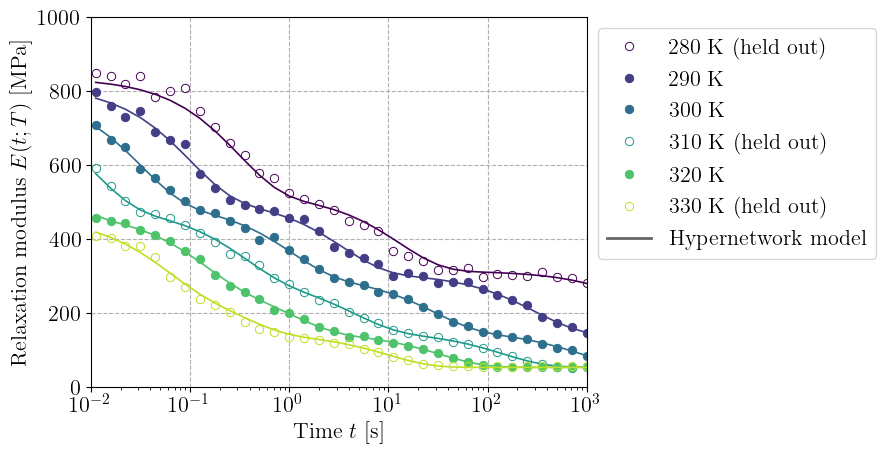

In [8]:
T_COLORS = plt.cm.viridis(np.linspace(0.0, 0.9, len(temperatures)))


def relaxation_plot(name, filename):
    fig, ax = plt.subplots()
    for k, T in enumerate(np.asarray(temperatures)):
        held = jnp.isin(T, held_out)
        ax.semilogx(
            t[window],
            E_data[k][window],
            "o",
            color=T_COLORS[k],
            mfc="none" if held else T_COLORS[k],
            mew=0.7,
            label=f"{T:.0f} K" + (" (held out)" if held else ""),
        )
        ax.semilogx(t[window], predictions[name][k][window], color=T_COLORS[k], lw=1.2)
    ax.plot([], [], color="0.4", label=f"{name} model")
    ax.set_xlabel("Time $t$ [s]")
    ax.set_ylabel(r"Relaxation modulus $E(t; T)$ [MPa]")
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}")
    plt.show()


relaxation_plot("Hypernetwork", "relaxation_hypernetwork")

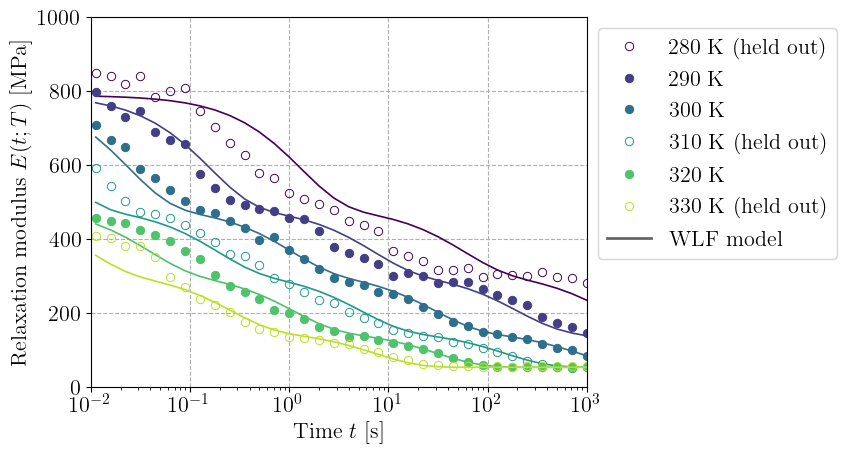

In [9]:
relaxation_plot("WLF", "relaxation_wlf")

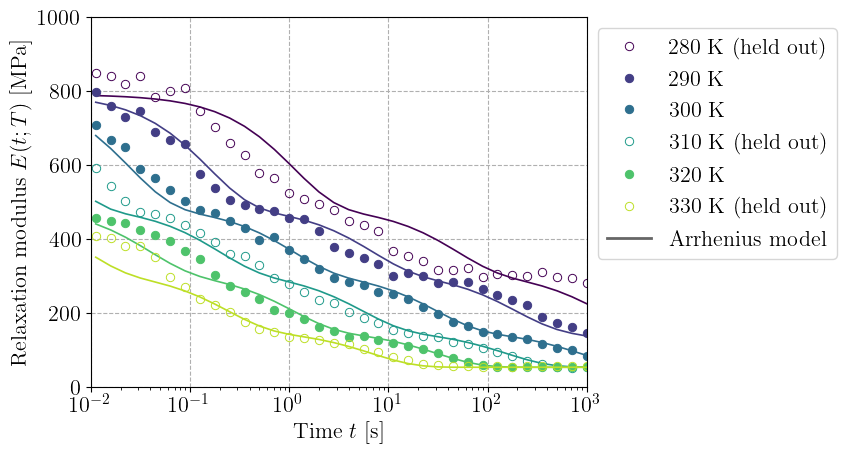

In [10]:
relaxation_plot("Arrhenius", "relaxation_arrhenius")

The next two figures show the Prony series generated by the hypernetwork as functions of the
temperature, against the reference material. The branches are sorted by increasing relaxation
time at $T_\text{ref}$. In the first figure, vertical lines mark the test temperatures, dashed for
the held-out ones; in the second, the dotted grey line is the equilibrium modulus of the
reference.

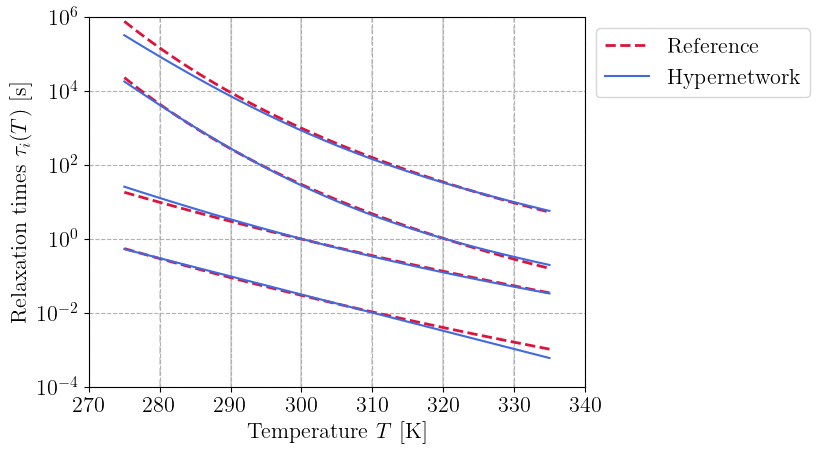

In [11]:
T_plot = jnp.linspace(275.0, 335.0, 121)
hyper = models["Hypernetwork"].behavior
tau_hyper = jax.vmap(hyper.relaxation_times.evaluate)(T_plot)
E_hyper = jax.vmap(hyper.viscous_branches.E.evaluate)(T_plot)
E_inf_hyper = jax.vmap(hyper.elasticity.E.evaluate)(T_plot)
order = jnp.argsort(hyper.relaxation_times.evaluate(jnp.asarray(T_REF)))
tau_reference = jax.vmap(ReferenceRelaxationTimes(tau_ref).evaluate)(T_plot)

fig, ax = plt.subplots()
for k in range(N):
    ax.semilogy(
        T_plot,
        tau_reference[:, k],
        color="crimson",
        lw=2.0,
        ls="--",
        label="Reference" if k == 0 else None,
    )
    ax.semilogy(
        T_plot,
        tau_hyper[:, order[k]],
        color=STYLE["Hypernetwork"]["color"],
        lw=1.5,
        label="Hypernetwork" if k == 0 else None,
    )
for T in np.asarray(temperatures):
    ax.axvline(
        T, color="0.85", lw=1.5, ls="--" if jnp.isin(T, held_out) else "-", zorder=0
    )
ax.set_xlabel("Temperature $T$ [K]")
ax.set_ylabel(r"Relaxation times $\tau_i(T)$ [s]")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ext in ("pdf", "png"):
    fig.savefig(f"relaxation_times.{ext}")
plt.show()

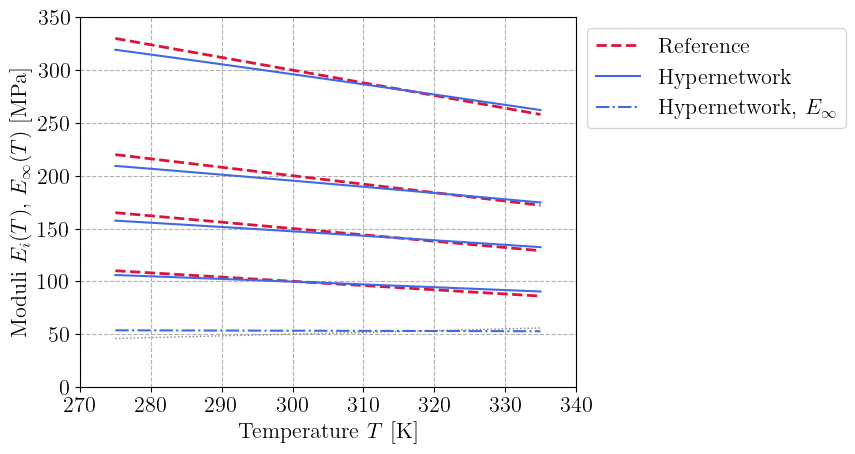

In [12]:
fig, ax = plt.subplots()
E_branches_reference = jax.vmap(reference_moduli["E_branches"].evaluate)(T_plot)
E_inf_reference = jax.vmap(reference_moduli["E_inf"].evaluate)(T_plot)
for k in range(N):
    ax.plot(
        T_plot,
        E_branches_reference[:, k],
        color="crimson",
        lw=2.0,
        ls="--",
        label="Reference" if k == 0 else None,
    )
    ax.plot(
        T_plot,
        E_hyper[:, order[k]],
        color=STYLE["Hypernetwork"]["color"],
        lw=1.5,
        label="Hypernetwork" if k == 0 else None,
    )
ax.plot(T_plot, E_inf_reference, color="0.5", lw=1.0, ls=":")
ax.plot(
    T_plot,
    E_inf_hyper,
    color=STYLE["Hypernetwork"]["color"],
    lw=1.5,
    ls="-.",
    label=r"Hypernetwork, $E_\infty$",
)
ax.set_ylim(0, None)
ax.set_xlabel("Temperature $T$ [K]")
ax.set_ylabel(r"Moduli $E_i(T)$, $E_\infty(T)$ [MPa]")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ext in ("pdf", "png"):
    fig.savefig(f"moduli.{ext}")
plt.show()

The last two figures show the extrapolation test at $t^* = 1$ s and $t^* = 100$ s; the training
range is shaded.

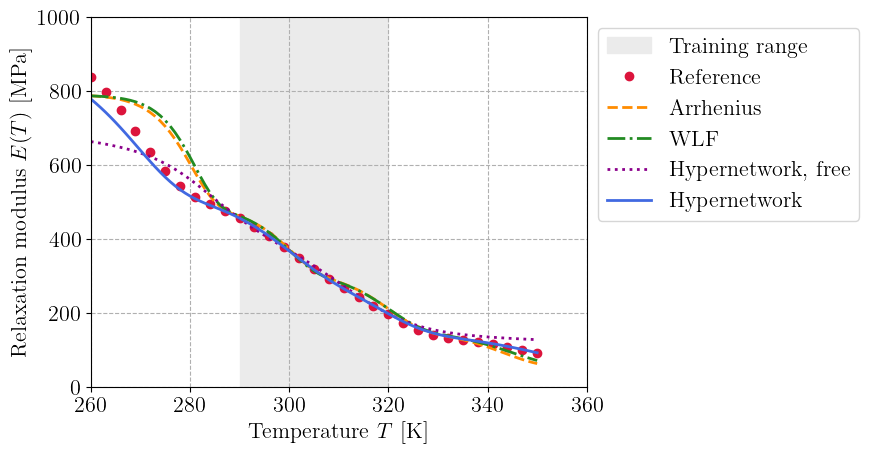

In [13]:
def sweep_plot(t_star, filename):
    fig, ax = plt.subplots()
    ax.axvspan(290.0, 320.0, color="0.92", zorder=0, label="Training range")
    ax.plot(
        T_sweep[::3],
        E_sweep_true[t_star][::3],
        "o",
        markerfacecolor=None,
        color="crimson",
        label="Reference",
    )
    for name, style in STYLE.items():
        ax.plot(T_sweep, E_sweep[name][t_star], lw=2.0, label=name, **style)
    ax.set_xlabel("Temperature $T$ [K]")
    ax.set_ylabel(rf"Relaxation modulus $E(T)$ [MPa]")
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}")
    plt.show()


sweep_plot(1.0, "sweep_1s")

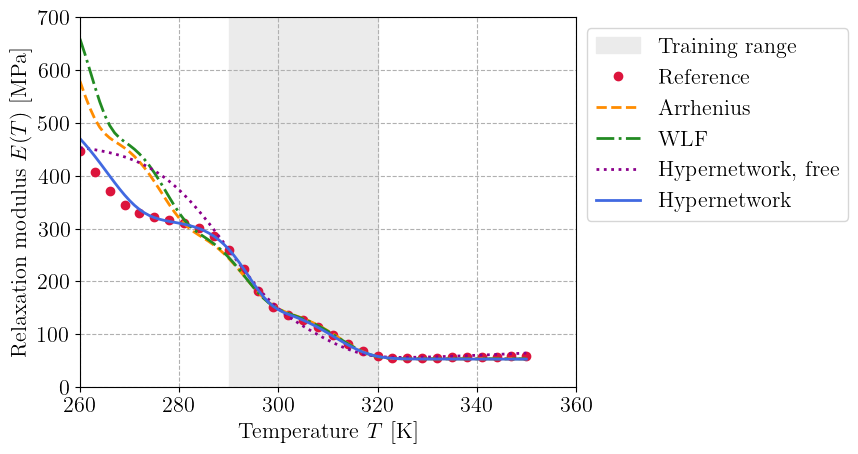

In [14]:
sweep_plot(100.0, "sweep_100s")

## Discussion

The values printed above are reported and discussed in the accompanying paper (section
"Parameter-level hybridization: a hypernetwork for thermoviscoelasticity").

The four models differ only in the modules placed in the coefficient fields of an unchanged
generalized Maxwell model. The `TemperatureDependent` wrapper extends its signature to
$(\boldsymbol\varepsilon, T)$ and evaluates these modules at the current temperature at each
step, the integration of the viscous strains over a step being that of the isothermal model.
With networks in these fields, the parameter modules form a hypernetwork that generates the whole
Prony series from the temperature. Calibration goes through the wrapper, the parameter modules
and the Maxwell update with the same automatic differentiation as for constant parameters.

A single shift factor with constant moduli cannot represent the reference material. The
Arrhenius and WLF models fit the training tests only approximately, and their errors increase on
the held-out tests; the calibrated shift laws are compromises between the two mechanisms of the
reference. The hypernetwork reproduces the training tests and the held-out tests, in
interpolation at 310 K and in extrapolation at 280 and 330 K. The relaxation times it generates
recover the two shift laws of the reference, and the moduli it generates recover the entropic
increase of $E_\infty$ and the decrease of the branch moduli.

The free hypernetwork fits the training tests equally well, but interpolates and extrapolates
poorly: with three training temperatures, parameters generated without constraint are not
determined away from the data. The structured hypernetwork generates relaxation times that
decrease with the temperature, with log-convex shift factors equal to one at $T_\text{ref}$,
properties shared by the Arrhenius and WLF laws, while leaving each branch its own law. These
constraints hold by construction on the generated quantities, with fewer parameters than the free
hypernetwork.

Outside the training range, the temperature laws are no longer constrained by the data. The
Arrhenius and WLF models overestimate the modulus at low temperature, their single shift law
slowing down the fast branches too much. The free hypernetwork drifts away from the reference on
both sides of the training range. The structured hypernetwork remains close to the reference over
the whole sweep: monotone, log-convex shift factors extrapolate in the same way as the physical
laws they generalize.